In [1]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error       # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split  # 정규화 클래스
from sklearn.preprocessing import StandardScaler

In [2]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [5]:
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)

In [8]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data[:2]
test_data[:2]

array([[22.],
       [40.]])

In [15]:
# 데이터 전처리 - 다항회귀
# train_data [[43.5**2, 43.5]]
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

In [16]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('무게예측 : ',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)
# 산점도 그래프

무게예측 :  [ 129.045957    891.91518321  830.62658318  891.91518321  830.62658318
  278.80805789 1123.94204082 1089.12708426  129.045957     71.96811598
  660.10688404  714.72243359  714.72243359  830.62658318]
train정확도 :  0.9686091136058282
test정확도 :  0.9541757735702354


In [30]:
in_data = 25
result = lr.predict([[in_data**2,in_data]])
print('예측무게 : ',result)

예측무게 :  [206.14294945]


In [17]:
print(lr.coef_, lr.intercept_)

[  1.11217508 -26.57323125] 175.3643060955132


In [27]:
lr.coef_[0]

np.float64(1.1121750795672076)

In [28]:
point = np.arange(15,50)

In [33]:
point

array([15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31,
       32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48,
       49])

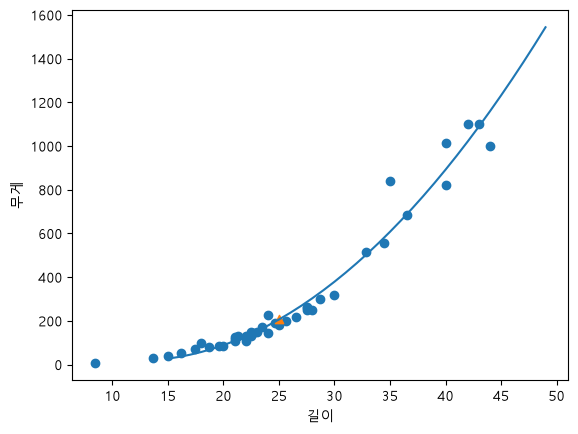

In [32]:
plt.scatter(train_data,train_label)
plt.scatter(25,208.83, marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [4]:
data = np.column_stack((perch_length,perch_weight))
data[:2]

array([[ 8.4,  5.9],
       [13.7, 32. ]])